In [1]:
#import libraries 
import pandas as pd 
from datasets import load_dataset 
import matplotlib.pyplot as plt 

#loading data 
dataset=load_dataset('lukebarousse/data_jobs') 
df=dataset['train'].to_pandas()  

#data cleanup 
df['job_posted_date']=pd.to_datetime(df['job_posted_date'])

'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/lukebarousse/data_jobs/resolve/ed776e5a0a8c40ea9d5efbd800772ae52e140f3e/data_jobs.py
Retrying in 1s [Retry 1/5].
Using the latest cached version of the dataset since lukebarousse/data_jobs couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'default' at C:\Users\USER\.cache\huggingface\datasets\lukebarousse___data_jobs\default\0.0.0\ed776e5a0a8c40ea9d5efbd800772ae52e140f3e (last modified on Tue Aug 25 12:49:19 2026).


In [2]:
df_US=df[df['job_country']=='United States'].copy()
df_US['job_posted_month']=df_US['job_posted_date'].dt.strftime('%B') 
df_US_pivot=df_US.pivot_table(index='job_posted_month',columns='job_title_short',aggfunc='size')

df_US_pivot.reset_index(inplace=True)
df_US_pivot['month_no']=pd.to_datetime(df_US_pivot['job_posted_month'],format='%B').dt.month
df_US_pivot.sort_values('month_no',inplace=True)
df_US_pivot.set_index('job_posted_month',inplace=True)
df_US_pivot.drop(columns='month_no',inplace=True)

df_US_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
January,527,36,8494,2655,6915,60,1544,773,1552,114
February,447,24,6124,3060,4956,56,1258,878,1127,90
March,438,19,6218,3183,4779,59,1114,829,1150,115
April,565,40,6049,2801,4867,51,1025,781,991,112
May,279,20,4993,2976,4377,49,839,746,914,90
June,446,32,5683,2893,4645,48,1009,812,1033,93
July,581,39,5201,2570,4876,65,883,747,1095,153
August,903,39,6634,3269,6318,68,1186,903,1515,194
September,897,50,4639,3224,4568,113,805,775,1014,228


In [9]:
df_US_software_pivot=pd.read_csv("https://lukeb.co/software_csv",index_col='job_posted_month')
df_US_software_pivot

,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
job_posted_month,,,,
January,13619,9827,5108,4348
February,11456,9116,7298,4284
March,11102,8178,5814,4159
April,14037,9209,7232,4220
May,12126,8864,6718,4980
June,12003,8065,5902,4781
July,11914,8061,6839,4344
August,11571,8191,7413,4104
September,14016,8447,6139,4094


In [12]:
df_Us_merged=df_US_pivot.merge(df_US_software_pivot,on='job_posted_month')

In [25]:
top_5=(df_Us_merged.sum()
       .sort_values(ascending=False)
       .head()
       .index
       .to_list())
top_5

['Front-End Developer',
 'Back-End Developer',
 'Full-Stack Developer',
 'Data Analyst',
 'Data Scientist']

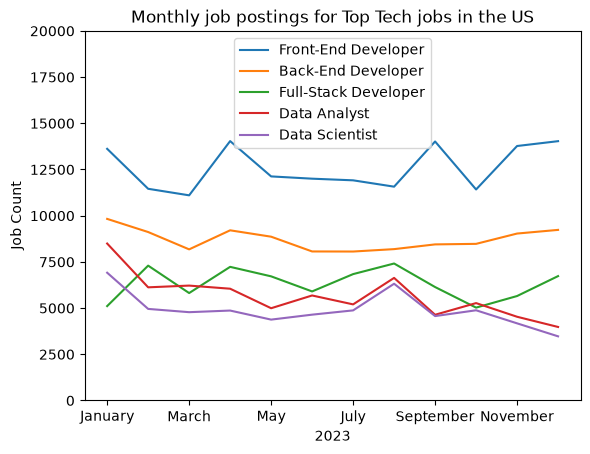

In [27]:
df_Us_merged[top_5].plot(kind='line')
plt.title('Monthly job postings for Top Tech jobs in the US')
plt.xlabel('2023')
plt.ylabel('Job Count') 
plt.ylim(0,20000)
plt.legend()
plt.show()